In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from pathlib import Path

In [8]:
df = pd.read_csv('../dataset/train.csv')
image_dir = Path('../dataset/train_images')
print("CSV images : ",len(df))
print("Image files : ",len(list(image_dir.glob('*'))))

CSV images :  3662
Image files :  3662


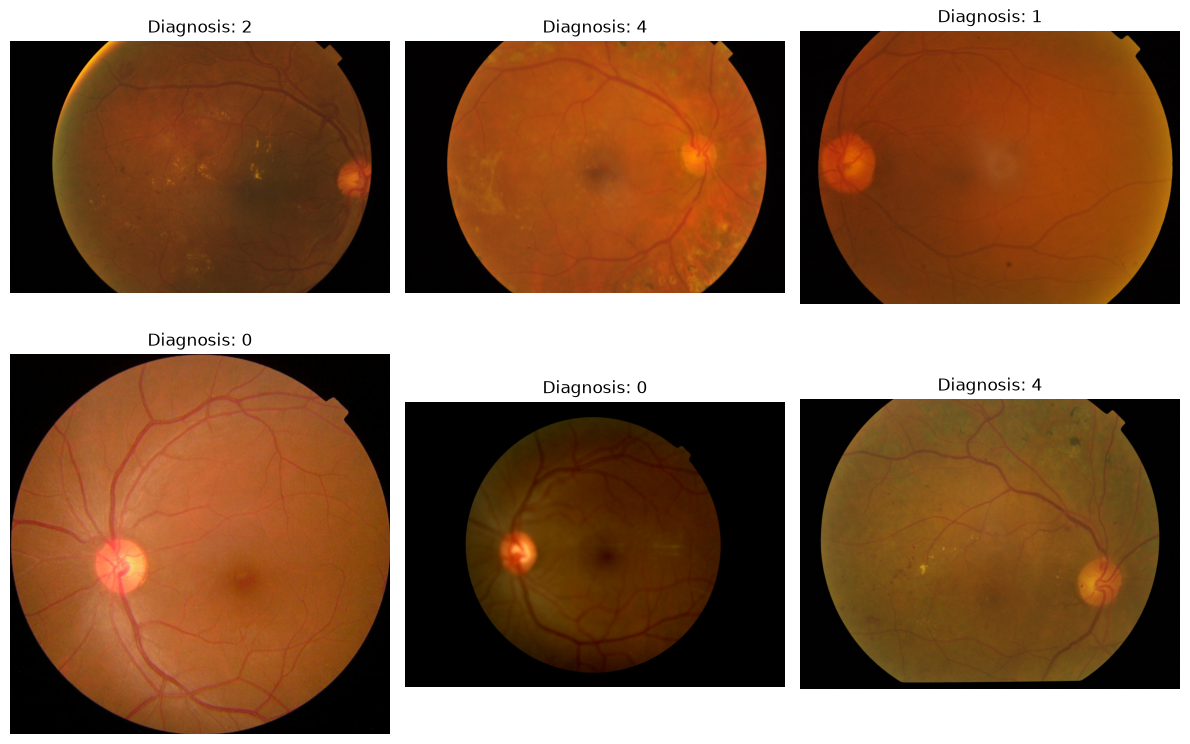

In [9]:
sample_ids = df["id_code"].head(6)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, image_id in zip(axes.ravel(), sample_ids):
    image_path = image_dir / f"{image_id}.png"
    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(f"Diagnosis: {df.loc[df['id_code'] == image_id, 'diagnosis'].iloc[0]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:


for image_id in df["id_code"].head(5):
    image_path = image_dir / f"{image_id}.png"
    image = Image.open(image_path)

    print(image_id, image.size)

000c1434d8d7 (3216, 2136)
001639a390f0 (3216, 2136)
0024cdab0c1e (2416, 1736)
002c21358ce6 (1050, 1050)
005b95c28852 (2048, 1536)


Original: (3216, 2136)
Processed: (224, 224)


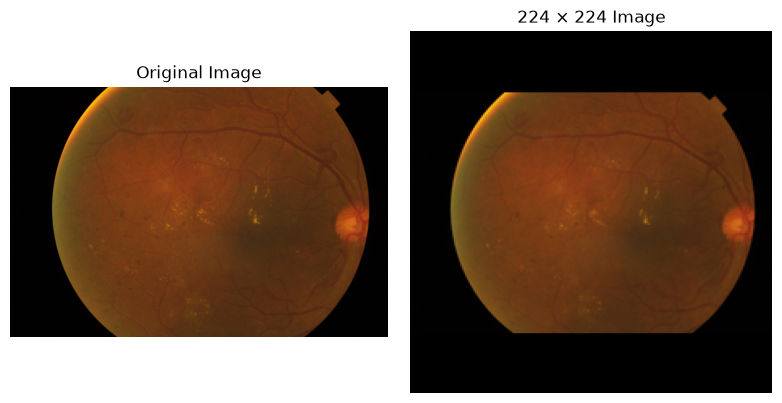

In [11]:
image_id = df.iloc[0]["id_code"]
image_path = image_dir / f"{image_id}.png"

img = Image.open(image_path).convert("RGB")

resized_img = ImageOps.pad(
    img,
    (224, 224),
    method=Image.Resampling.LANCZOS
)

print("Original:", img.size)
print("Processed:", resized_img.size)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_img)
plt.title("224 × 224 Image")
plt.axis("off")

plt.tight_layout()
plt.show()

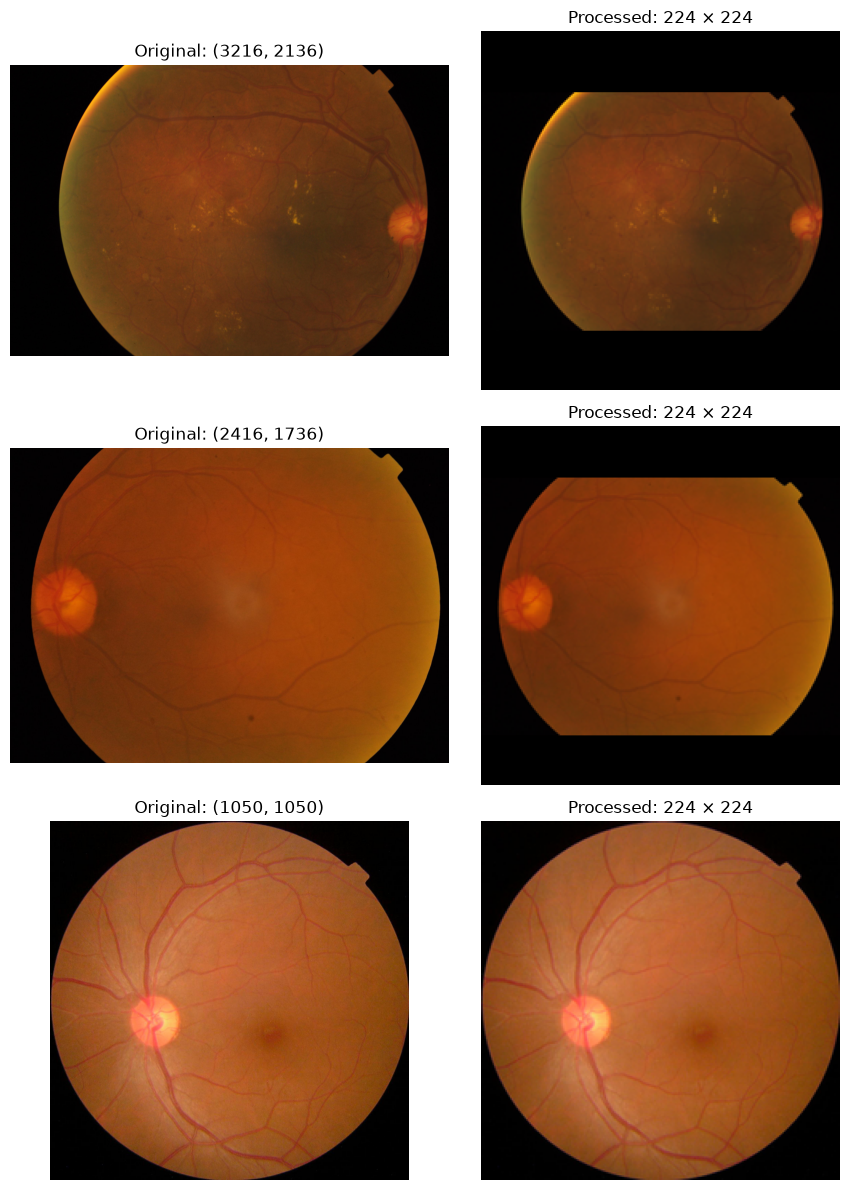

In [12]:
indices = [0, 2, 3]

fig, axes = plt.subplots(3, 2, figsize=(9, 12))

for row, idx in enumerate(indices):

    image_id = df.loc[idx, "id_code"]
    image_path = image_dir / f"{image_id}.png"

    original = Image.open(image_path).convert("RGB")

    processed = ImageOps.pad(
        original,
        (224, 224),
        method=Image.Resampling.LANCZOS
    )

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"Original: {original.size}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(processed)
    axes[row, 1].set_title("Processed: 224 × 224")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

000c1434d8d7: Original=(3216, 2136), Image area after padding=66.52%
0024cdab0c1e: Original=(2416, 1736), Image area after padding=71.88%
002c21358ce6: Original=(1050, 1050), Image area after padding=100.00%
005b95c28852: Original=(2048, 1536), Image area after padding=75.00%


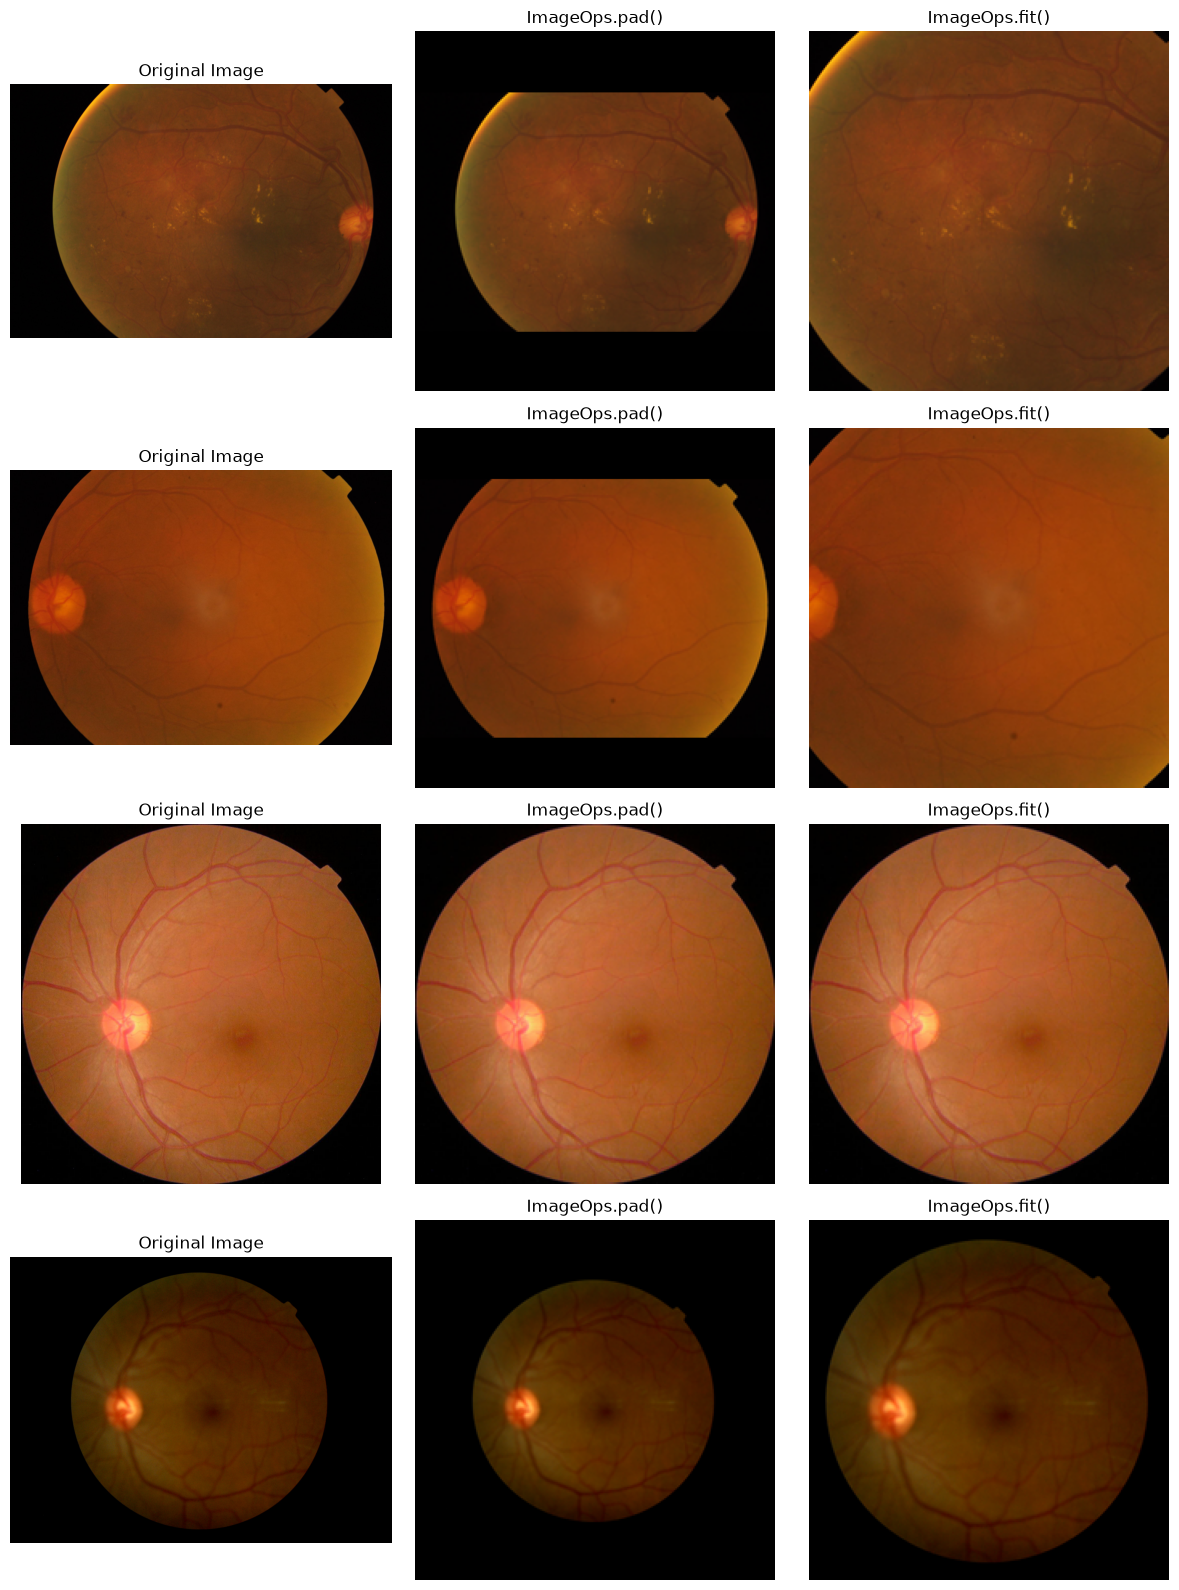

In [13]:


# Select four sample images
sample_indices = [0, 2, 3, 4]

fig, axes = plt.subplots(
    len(sample_indices),
    3,
    figsize=(12, 16)
)

for row, idx in enumerate(sample_indices):

    # Get image ID
    image_id = df.loc[idx, "id_code"]

    # Load original image
    image_path = image_dir / f"{image_id}.png"

    original = Image.open(image_path).convert("RGB")

    # Method 1: Direct resizing
    direct_resize = original.resize(
        (224, 224),
        Image.Resampling.LANCZOS
    )

    # Method 2: Aspect-ratio-preserving padding
    padded = ImageOps.pad(
        original,
        (224, 224),
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0)
    )

    # Method 3: Aspect-ratio-preserving centre crop
    cropped = ImageOps.fit(
        original,
        (224, 224),
        method=Image.Resampling.LANCZOS,
        centering=(0.5, 0.5)
    )

    # Calculate how much of the padded image contains
    # the resized original image rather than added padding.
    contained = ImageOps.contain(
        original,
        (224, 224),
        method=Image.Resampling.LANCZOS
    )

    content_percentage = (
        contained.width * contained.height
        / (224 * 224)
    ) * 100

    print(
        f"{image_id}: "
        f"Original={original.size}, "
        f"Image area after padding={content_percentage:.2f}%"
    )

    # Display original image
    axes[row, 0].imshow(original)
    axes[row, 0].set_title("Original Image")

    # Display padded image
    axes[row, 1].imshow(padded)
    axes[row, 1].set_title("ImageOps.pad()")

    # Display cropped image
    axes[row, 2].imshow(cropped)
    axes[row, 2].set_title("ImageOps.fit()")

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [14]:
from sklearn.model_selection import train_test_split

# Split dataset into training and validation
train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["diagnosis"]
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("\nTraining class distribution:")
print(train_df["diagnosis"].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_df["diagnosis"].value_counts().sort_index())

Training images: 2929
Validation images: 733

Training class distribution:
diagnosis
0    1444
1     296
2     799
3     154
4     236
Name: count, dtype: int64

Validation class distribution:
diagnosis
0    361
1     74
2    200
3     39
4     59
Name: count, dtype: int64
